In [2]:
library(ggplot2)
library(ggrepel)
library(data.table)
library(dplyr)
library(rlang)

In [ ]:
setwd("./real_data_CSA_AFR")

In [9]:
info_afr = read.csv('AFR_data_info.csv', row.names = 1)

data_summary_exp = info_afr[is.na(info_afr$AFR.controls),]
data_summary_out = info_afr[!is.na(info_afr$AFR.controls),]

ts1 = data_summary_exp$EUR.phecode
ts2 = data_summary_out$EUR.phecode

pairs <- rbind(
    expand.grid(exposure = ts1, outcome = ts2, stringsAsFactors = FALSE),
    expand.grid(exposure = ts2, outcome = ts1, stringsAsFactors = FALSE),
    subset(expand.grid(exposure = ts2, outcome = ts2, stringsAsFactors = FALSE), exposure != outcome)
)

code_to_trait = setNames(info_afr$EUR.phenotype, info_afr$EUR.phecode)

### arrange results

In [19]:
# Helper function
load_and_rename <- function(file, cols, suffix, select_cols = c('exposure','outcome','Threshold','nIV','beta','beta.se','beta.pvalue')) {
    df <- fread(file)
    colnames(df) <- cols
    # Special processing for certain columns
    if ("stat" %in% cols) df$beta.se <- abs(df$beta / sqrt(-df$stat))
    if ("pi0" %in% cols)  df$nvalid <- df$nIV * df$pi0
    if (all(c("CL","CU") %in% cols)) df$beta.se <- (df$CU - df$CL) / (2 * qnorm(1 - 0.05 / 2))
    
    df <- as.data.frame(df)[, select_cols, drop = FALSE]
    colnames(df)[3:ncol(df)] <- paste0(colnames(df)[3:ncol(df)], "_", suffix)
    return(df)
}

# Main pipeline: dataset = "AFR_results" / "EUR_results_in_AFR"
build_merged <- function(dataset_folder = "AFR_results", has_xmr = TRUE) {
    dir <- paste0("./", dataset_folder, "/")
    
    df_list <- list()
    
    # --- XMR ---
    if (has_xmr) {
        df_xmr <- fread(paste0(dir, "XMR.MRres"))
        df0 <- as.data.frame(df_xmr)[, c('exposure','outcome','exp_N1','exp_N2','Threshold','nIV','nvalid','beta','beta.se','beta.pvalue')]
        colnames(df0)[5:10] <- paste0(colnames(df0)[5:10], "_XMR")
        df_list[["XMR"]] <- df0
    }
    
    # --- TEMR ---
    df_list[["TEMR"]] <- load_and_rename(
        paste0(dir, "TEMR.MRres"),
        cols = c("exposure","outcome","beta","beta.pvalue","stat","nIV","Threshold"),
        suffix = "TEMR"
    )
    
    # --- MRAPSS ---
    df_list[["MRAPSS"]] <- load_and_rename(
        paste0(dir, "MRAPSS.MRres"),
        cols = c("exposure","outcome","beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold"),
        suffix = "MRAPSS",
        select_cols = c('exposure','outcome','Threshold','nIV','nvalid','beta','beta.se','beta.pvalue')
    )
    
    # --- Standard 7-column methods ---
    std7 <- list(
        IVW       = "IVW.MRres",
        Egger     = "Egger.MRres",
        `Weighted-mode`   = "Weightmode.MRres",
        `Weighted-median`  = "Weightmed.MRres"
    )
    std7_cols <- c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
    
    for (method in names(std7)) {
        df_list[[method]] <- load_and_rename(
            paste0(dir, std7[[method]]),
            cols = std7_cols,
            suffix = method
        )
    }
    
    # --- Standard 8-column methods ---
    std8 <- list(
        IVW_fe     = "IVW_fe.MRres",
        MRMix      = "MRMix.MRres",
        `MR-Robust`  = "MR-Robust.MRres",
        `MR-Lasso`   = "MR-Lasso.MRres",
        `cML-MA`     = "cML-MA.MRres",
        `MR-PRESSO`  = "MR-PRESSO.MRres",
        dIVW       = "dIVW.MRres"
    )
    std8_cols <- c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")
    
    for (method in names(std8)) {
        df_list[[method]] <- load_and_rename(
            paste0(dir, std8[[method]]),
            cols = std8_cols,
            suffix = method
        )
    }
    
    # --- CAUSE ---
    df_list[["CAUSE"]] <- load_and_rename(
        paste0(dir, "CAUSE.MRres"),
        cols = c('exposure','outcome','beta.pvalue','Threshold','nIV','beta','beta.se','method'),
        suffix = "CAUSE"
    )
    
    # --- ConMix ---
    df_list[["ConMix"]] <- load_and_rename(
        paste0(dir, "ConMix.MRres"),
        cols = c('exposure','outcome','method','Threshold','nIV','beta','beta.pvalue','CL','CU'),
        suffix = "ConMix",
        select_cols = c('exposure','outcome','Threshold','nIV','beta','beta.se','beta.pvalue','CL','CU')
    )
    
    # --- Merge all data frames ---
    df_all <- Reduce(function(x, y) merge(x, y, all = TRUE), df_list)
    
    write.csv(df_all, paste0(dir, dataset_folder, ".csv"), row.names = FALSE)
    return(df_all)
}

##############################
# Run
##############################
df_all_AFR  <- build_merged("AFR_results",  has_xmr = TRUE)
df_all_EUR  <- build_merged("EUR_results_in_AFR",  has_xmr = FALSE)

In [27]:
plot_mr_scatter <- function(
    df_all,
    info,
    method,
    pairs = NULL,
    code_col = "EUR.phecode",
    cat_col  = "Category",
    code_to_abbr = NULL,
    plot = FALSE,
    color_map = c(
        "black" = "black", 
        "Anthropometric" = "#F8766D", 
        "Blood cell" = "#7CAE00",
        "Disease" = "#00BE67",
        "Inflammatory" = "#00BFC4",
        "Metabolic" = "#C77CFF",
        "Protein" = "#FF61CC"
    ),
    title = method,
    max_y = 10,
    xl = -1, xr = 1.2,
    size_large = 10,
    size_small = 4.5,
    max_labels = NULL,
    box.padding = 1.6,
    segment.size = 0.5,
    min.segment.length = 0,
    force = 5.5,
    force_pull = 0.19,
    size_text = 10,
    legend_pos = "none",
    add_text = TRUE,
    label_assign = FALSE,
    label_x = NULL,
    label_y = NULL
) {

    # ===== 1. Extract method-specific beta & p-value columns =====
    beta_var <- paste0("beta_", method)
    pval_var <- paste0("beta.pvalue_", method)
    if (!all(c(beta_var, pval_var) %in% colnames(df_all))) {
        stop("Column(s) '", beta_var, "' / '", pval_var, "' not found in df_all.")
    }

    data <- data.frame(
        exposure    = df_all[["exposure"]],
        outcome     = df_all[["outcome"]],
        beta        = as.numeric(df_all[[beta_var]]),
        beta.pvalue = as.numeric(df_all[[pval_var]]),
        stringsAsFactors = FALSE
    )

    # ===== 2. Filter to specified exposure-outcome pairs =====
    if (!is.null(pairs)) {
        data <- merge(data, pairs[, c("exposure", "outcome")], by = c("exposure", "outcome"))
    }

    # ===== 3. Map trait metadata from info =====
    cat_lookup  <- setNames(info[[cat_col]],  info[[code_col]])

    data$exposure_cat  <- cat_lookup[data$exposure]
    data$outcome_cat   <- cat_lookup[data$outcome]

    # ===== 4. Map abbreviations =====
    if (!is.null(code_to_abbr)) {
        data$exp_abbr <- code_to_abbr[data$exposure]
        data$out_abbr <- code_to_abbr[data$outcome]
    } else {
        data$exp_abbr <- data$exposure
        data$out_abbr <- data$outcome
    }

    # ===== 5. Remove NAs, cap small p-values, compute FDR =====
    data <- na.omit(data)
    if (nrow(data) == 0) { warning("No data left after NA removal."); return(invisible(NULL)) }

    data$beta.pvalue[data$beta.pvalue < 10^(-max_y)] <- 10^(-max_y)
    data$qval <- p.adjust(data$beta.pvalue, method = "BH")
    data$FDR_significant <- data$qval < 0.05

    # ===== 6. Derived columns =====
    data$exp_out_abbr <- paste0(data$exp_abbr, " to ", data$out_abbr)
    data$log_pval     <- -log10(data$beta.pvalue)

    data$sig_type <- "P > 0.05"
    data$sig_type[data$beta.pvalue < 0.05] <- "P < 0.05"
    data$sig_type[data$qval < 0.05]        <- "P(BH) < 0.05"
    data$sig_type <- factor(data$sig_type, levels = c("P > 0.05", "P < 0.05", "P(BH) < 0.05"))

    # Color: category for nominally significant, black otherwise
    data$colors <- "black"
    data$colors[data$beta.pvalue < 0.05] <- data$exposure_cat[data$beta.pvalue < 0.05]

    # Ensure every color value present in data is covered by color_map
    missing <- setdiff(unique(data$colors), names(color_map))
    if (length(missing) > 0) {
        warning("Categories missing from color_map (defaulting to grey): ", paste(missing, collapse = ", "))
        for (m in missing) color_map[m] <- "grey50"
    }

    # ===== 7. Build label data =====
    label_data <- data.frame()
    if (add_text) {
        if (!label_assign) {
            # Auto-select top-N points per category by -log10(p)
            label_data <- data %>%
                            filter(.data$colors %in% names(max_labels)) %>%
                            group_split(.data$colors) %>%
                            purrr::map_dfr(function(df) {
                            cat_name <- df$colors[1]
                            df %>%
                              arrange(desc(log_pval)) %>%
                              head(max_labels[cat_name])
                          })

            
        } else {
            # Manually specified pairs
            label_list <- lapply(seq_along(label_x), function(i) {
                data[data$exposure == label_x[i] & data$outcome == label_y[i], ]
            })
            label_data <- bind_rows(label_list)
        }
    }

    # ===== 8. Color scale: legend only for non-black categories present in data =====
    cat_in_data  <- setdiff(unique(data$colors), "black")
    color_breaks <- intersect(names(color_map), cat_in_data)

    # ===== 9. Assemble ggplot =====
    p <- ggplot(data, aes(x = beta, y = log_pval)) +
        geom_point(
            aes(color = colors, size = sig_type, alpha = sig_type),
            shape = 16, stroke = 1.5
        ) +
        scale_color_manual(
            values = color_map,
            breaks = color_breaks,
            labels = color_breaks
        ) +
        scale_size_manual(
            values = c("P > 0.05" = size_small, "P < 0.05" = size_small, "P(BH) < 0.05" = size_large)
        ) +
        scale_alpha_manual(
            name   = "Significance",
            values = c("P > 0.05" = 0.8, "P < 0.05" = 0.7, "P(BH) < 0.05" = 0.5)
        )


    if (legend_pos != "none") {
        # Use nrow for bottom/top, ncol for left/right
        is_horizontal <- legend_pos %in% c("bottom", "top")

        p <- p + guides(
            color = guide_legend(
                nrow = if (is_horizontal) 1 else NULL,
                ncol = if (!is_horizontal) 1 else NULL,
                override.aes = list(size = 5, alpha = 1),
                order = 1
            ),
            size = guide_legend(
                nrow = if (is_horizontal) 1 else NULL,
                ncol = if (!is_horizontal) 1 else NULL,
                title = "",
                order = 2,
                override.aes = list(color = c("black", "#FF61CC", "#FF61CC"))
            ),
            alpha = guide_legend(
                nrow = if (is_horizontal) 1 else NULL,
                ncol = if (!is_horizontal) 1 else NULL,
                title = "",
                order = 2
            )
        )
    }
    
    
    
    p <- p +
        geom_vline(xintercept = 0, linetype = "dashed") +
        labs(
            x     = expression("Effect size (" * hat(beta) * ")"),
            y     = expression(paste("-log"[10], plain(P))),
            color = "Exposure category",
            shape = "", size = "", alpha = ""
        ) +
        theme_minimal() +
        theme(
            plot.title        = element_text(size = 35, hjust = 0.5),
            axis.line.x       = element_line(size = 0.9, color = "black"),
            axis.line.y       = element_line(size = 0.9, color = "black"),
            axis.text.x       = element_text(size = 24),
            axis.text.y       = element_text(size = 24),
            axis.title.y      = element_text(size = 30),
            axis.title.x      = element_text(size = 24),
            axis.ticks         = element_line(size = 1.9),
            legend.text        = element_text(size = 15),
            legend.position    = legend_pos,
            legend.key.size    = unit(2, "lines"),
            legend.key.height  = unit(1.5, "cm"),
            legend.key.width   = unit(1.5, "cm"),
            legend.spacing.x   = unit(2.0, "cm"),
            legend.title       = element_text(size = 20),
            panel.grid         = element_blank(),
            panel.border       = element_rect(color = "black", fill = NA, size = 2.2)
        ) +
        ggtitle(title) +
        xlim(xl, xr) +
        ylim(0, max_y)

    if (add_text && nrow(label_data) > 0) {
        p <- p + geom_text_repel(
            data = label_data,
            aes(label = exp_out_abbr, color = colors),
            size               = size_text,
            max.overlaps       = 23,
            box.padding        = box.padding,
            segment.size       = segment.size,
            min.segment.length = min.segment.length,
            force              = force,
            force_pull         = force_pull,
            show.legend        = FALSE
        )
    }

    if(plot) print(p)

    dir.create('./plots/AFR_scatter', recursive = TRUE, showWarnings = FALSE)
    ggsave(paste0('./plots/AFR_scatter/',method,'.png'), plot = p, width = 20, height = 16, bg='white')

}

### START

### Fig. 6B

#### save figures in ./plots/AFR_scatter/

In [21]:
# Abbreviation mapping — adjust codes/order to match your info_afr
code_to_abbr <- setNames(
    c('Asthma','CIHD','T2D','IGF-1','SHBG','Vit D',
      'CRP','LDLC','TG','HTN','DLM','Neutro','ALB'),
    info_afr$EUR.phecode   # make sure the order matches the abbreviations above
)

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”
Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""


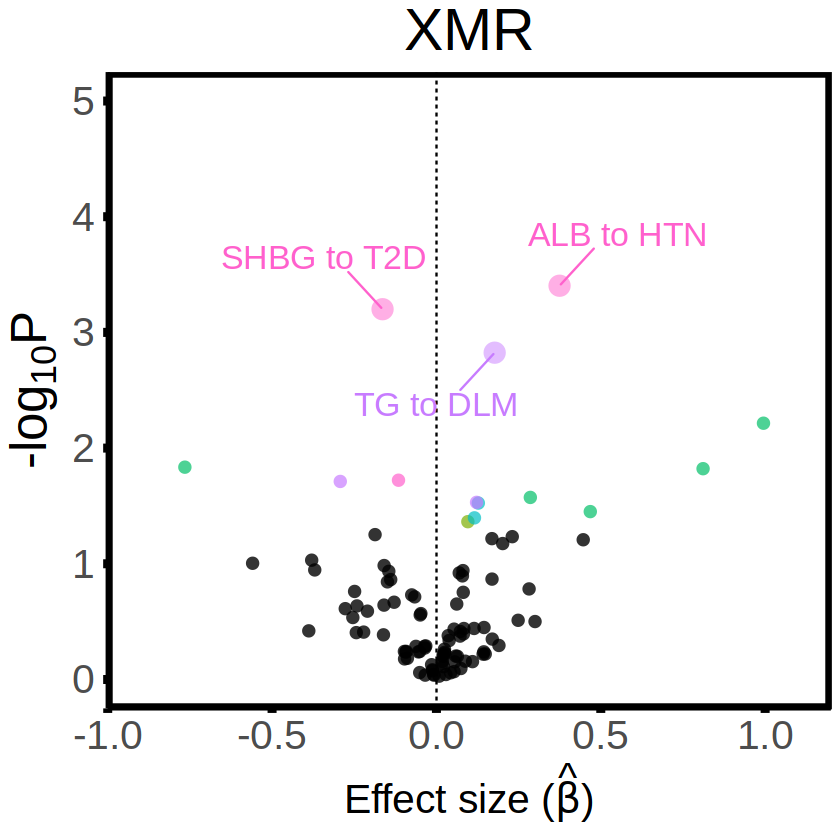

Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""


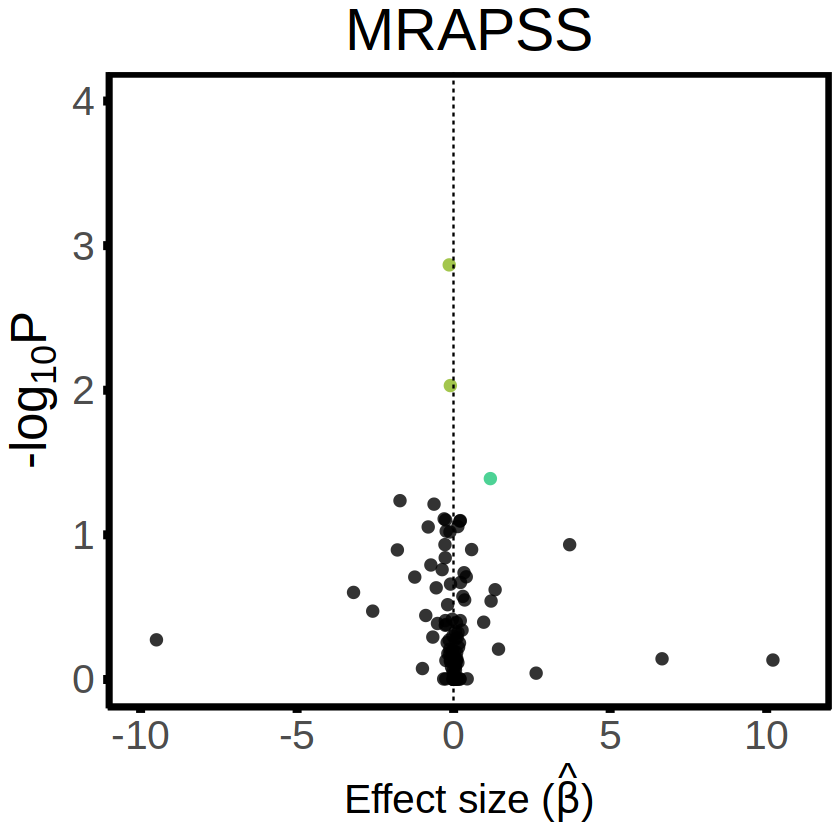

Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""


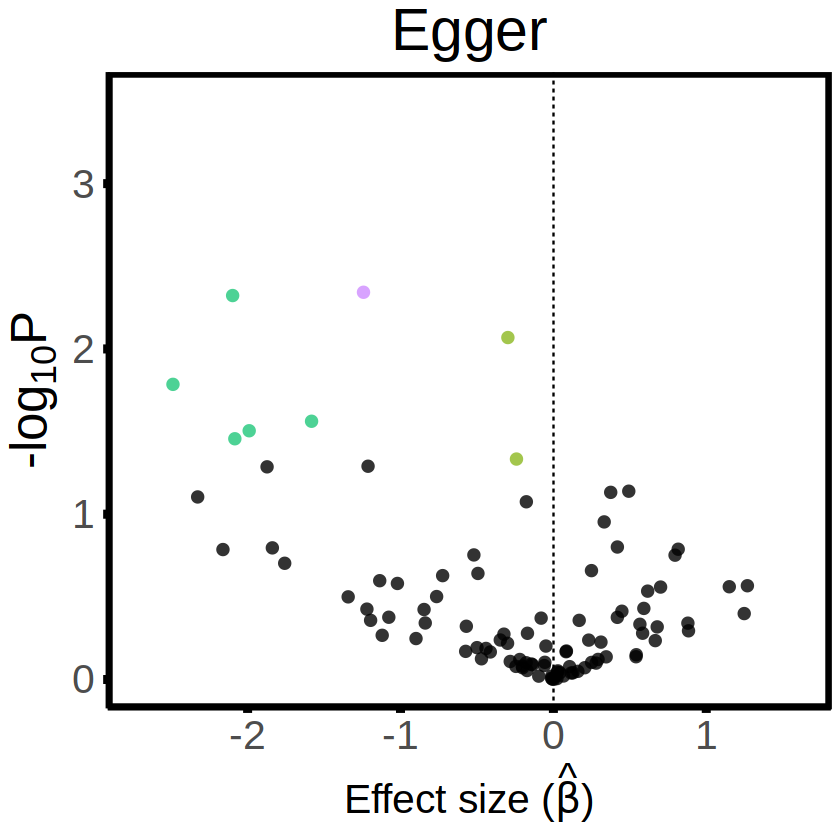

Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""


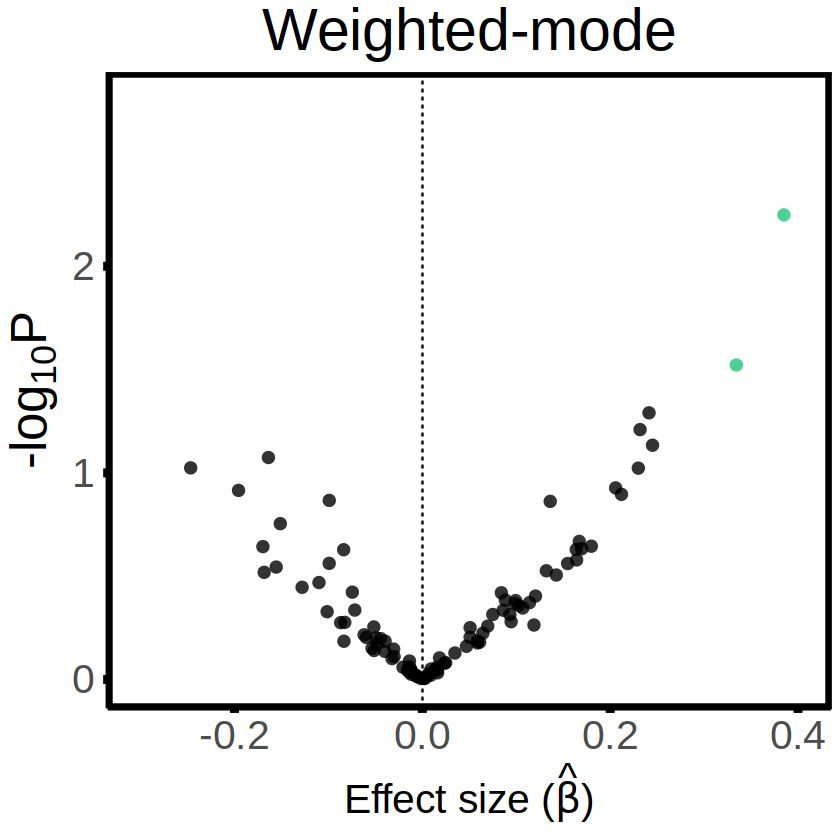

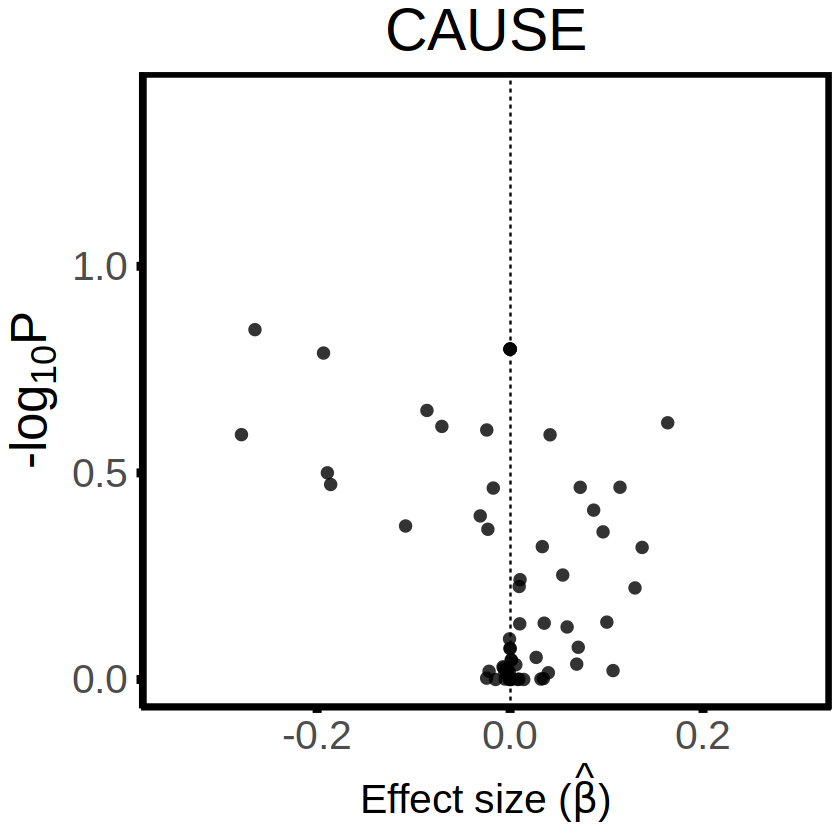

In [28]:
method_list = c('XMR', 'MRAPSS', 'Egger', 'Weighted-mode', 'CAUSE')


# ========== Plot XMR ==========
plot_mr_scatter(
    df_all = df_all_AFR, info = info_afr, method = 'XMR', pairs = pairs,
    code_col = "EUR.phecode", cat_col = "Category",
    code_to_abbr = code_to_abbr,
    plot = TRUE,
    title = 'XMR', max_y = 5, xl=-0.9, xr=1.1,
    size_large = 5, size_small = 2.5,
    size_text = 7,
    legend_pos = "none", add_text = TRUE, label_assign = FALSE,
    max_labels =  c("Anthropometric" = 0, "Blood cell" = 0,"Disease" = 0, 
                    "Inflammatory" = 0, "Metabolic" = 1, "Protein" = 2)
)


plot_mr_scatter(
    df_all = df_all_AFR, info = info_afr, method = 'MRAPSS', pairs = pairs,
    code_col = "EUR.phecode", cat_col = "Category",
    code_to_abbr = code_to_abbr,
    plot = TRUE,
    title = 'MRAPSS', max_y = 4, xl=-10, xr=11,
    size_large = 5, size_small = 2.5,
    size_text = 7,
    legend_pos = "none", add_text = TRUE, label_assign = TRUE
)
    

plot_mr_scatter(
    df_all = df_all_AFR, info = info_afr, method = "Egger", pairs = pairs,
    code_col = "EUR.phecode", cat_col = "Category",
    code_to_abbr = code_to_abbr,
    plot = TRUE,
    title = "Egger", max_y = 3.5, xl=-2.7, xr=1.6,
    size_large = 5, size_small = 2.5,
    size_text = 7,
    legend_pos = "none", add_text = TRUE, label_assign = TRUE
)


plot_mr_scatter(
    df_all = df_all_AFR, info = info_afr, method = 'Weighted-mode', pairs = pairs,
    code_col = "EUR.phecode", cat_col = "Category",
    code_to_abbr = code_to_abbr,
    plot = TRUE,
    title = 'Weighted-mode', max_y = 2.8, xl=-0.3, xr=0.4,
    size_large = 5, size_small = 2.5,
    size_text = 7,
    legend_pos = "none", add_text = TRUE, label_assign = TRUE
)


plot_mr_scatter(
    df_all = df_all_AFR, info = info_afr, method = 'CAUSE', pairs = pairs,
    code_col = "EUR.phecode", cat_col = "Category",
    code_to_abbr = code_to_abbr,
    plot = TRUE,
    title = 'CAUSE', max_y = 1.4, xl=-0.35, xr=0.3,
    size_large = 5, size_small = 2.5,
    size_text = 7,
    legend_pos = "none", add_text = TRUE, label_assign = TRUE
)

In [29]:
method_list = c('TEMR', 'IVW', 'Weighted-median', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

method_name_list = method_list


for(i in 1:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
    
    plot_mr_scatter(
        df_all = df_all_AFR, info = info_afr, method = method, pairs = pairs,
        code_col = "EUR.phecode", cat_col = "Category",
        code_to_abbr = code_to_abbr,
        plot = FALSE,
        title = method, max_y = 10, xl = -1, xr = 1.2,
        size_large = 5, size_small = 2.5,
        size_text = 7,
        legend_pos = "none", add_text = FALSE, label_assign = TRUE
    )
    
}


Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""
Ignoring unknown labels:
• shape : ""


### Fig. 6D

### save figures in ./plots/AFR_EUR/

In [30]:
plot_scatter_AFR_EUR <- function(df_afr, df_eur,
                                  beta_afr, beta_eur,
                                  pval_afr, pval_eur,
                                  se_afr, se_eur,
                                  method_name,
                                  code_to_abbr,
                                  merge_cols = c("exposure", "outcome"),
                                  plot = TRUE,
                                  legend_pos = c(0.73, 0.12),
                                  max_labels = c("both significant" = 8, 
                                                 "only EUR significant" = 5, 
                                                 "only AFR significant" = 5),
                                  label_exclude = NULL,
                                  label_include = NULL,
                                  x_lim=NULL,
                                  xl=0,
                                  xr=0){
    
    print(method_name)
    
    
    # ---- 1. Merge AFR and EUR data ----
    keep_cols1 <- c(merge_cols, beta_afr, pval_afr, se_afr)
    keep_cols2 <- c(merge_cols, beta_eur, pval_eur, se_eur)
    
    temp1 = df_afr[, keep_cols1]
    temp2 = df_eur[, keep_cols2]
    
    colnames(temp1) = c("exposure", "outcome", "beta", "pval", "se")
    colnames(temp2) = c("exposure", "outcome", "beta", "pval", "se")
    
    df <- merge(temp1, temp2,
                by = merge_cols, suffixes = c(".x", ".y"))
     
    
    max_y <- 15
    
    # ---- 2. Process p-values and FDR correction ----
    process_pval <- function(pval) {
        pval[pval < 10^(-max_y) & !is.na(pval)] <- 10^(-max_y)
        qval <- p.adjust(pval, method = "BH")
        return(list(pval = pval, qval = qval, 
                    sig = ifelse(is.na(qval), FALSE, qval < 0.05)))
    }
    
    # AFR (x)
    res_x <- process_pval(df$pval.x)
    df$pval.x <- res_x$pval; df$qval.x <- res_x$qval; df$FDR_significant.x <- res_x$sig
    
    # EUR (y)
    res_y <- process_pval(df$pval.y)
    df$pval.y <- res_y$pval; df$qval.y <- res_y$qval; df$FDR_significant.y <- res_y$sig
    
    df <- na.omit(df)
    
    # ---- 3. Keep only pairs significant in at least one population ----
    df <- df[df$FDR_significant.x | df$FDR_significant.y, ]
    
    # ---- 4. Abbreviations ----
    df$exp_abbr <- code_to_abbr[df$exposure]
    df$out_abbr <- code_to_abbr[df$outcome]
    df$exp_out_abbr <- paste0(df$exp_abbr, " to ", df$out_abbr)
    
    # ---- 5. Classification ----
    df$class <- "1"
    df$class[df$FDR_significant.x & df$FDR_significant.y]  <- "both significant"
    df$class[df$FDR_significant.x & !df$FDR_significant.y] <- "only AFR significant"
    df$class[!df$FDR_significant.x & df$FDR_significant.y] <- "only EUR significant"
    
    df_pair <- df
    
    # ---- 6. Select labels (safe loop, avoids slice_head bug) ----
    label_data_list <- list()
    for (group in names(max_labels)) {
        group_data <- df_pair %>%
            filter(class == group) %>%
            arrange(desc(abs(beta.x - beta.y))) %>%
            head(max_labels[group])
        label_data_list[[group]] <- group_data
    }
    label_data <- bind_rows(label_data_list)
    
    # Exclude specific labels
    if (!is.null(label_exclude) && nrow(label_exclude) > 0) {
        exclude_keys <- paste(label_exclude$exposure, label_exclude$outcome, sep = "_")
        label_keys   <- paste(label_data$exposure, label_data$outcome, sep = "_")
        label_data   <- label_data[!label_keys %in% exclude_keys, ]
    }
    # Include specific labels
    if (!is.null(label_include) && nrow(label_include) > 0) {
        include_keys  <- paste(label_include$exposure, label_include$outcome, sep = "_")
        pair_keys     <- paste(df_pair$exposure, df_pair$outcome, sep = "_")
        rows_to_add   <- df_pair[pair_keys %in% include_keys, ]
        existing_keys <- paste(label_data$exposure, label_data$outcome, sep = "_")
        rows_to_add   <- rows_to_add[!paste(rows_to_add$exposure, rows_to_add$outcome, sep = "_") %in% existing_keys, ]
        label_data    <- rbind(label_data, rows_to_add)
    }
    
    # ---- 7. Build plot ----
    p <- ggplot(df_pair, aes(x = beta.x, y = beta.y, color = class)) +
        geom_point(aes(alpha = class), size = 3) +
        geom_errorbar(aes(ymin = beta.y - 1.96 * se.y, ymax = beta.y + 1.96 * se.y, alpha = class),
                      width = 0.02, size = 0.3) +
        geom_errorbarh(aes(xmin = beta.x - 1.96 * se.x, xmax = beta.x + 1.96 * se.x, alpha = class),
                       height = 0.02, size = 0.3) +
        geom_hline(yintercept = 0, size = 1., linetype = "dotted", color = "grey") +
        geom_vline(xintercept = 0, size = 1., linetype = "dotted", color = "grey") +
        geom_abline(slope = 1, intercept = 0, color = "black", linetype = "dashed", size = 0.8) +
        geom_text_repel(data = label_data,
                        aes(label = exp_out_abbr),
                        size = 6,
                        max.overlaps = 26,
                        box.padding = 1.3,
                        segment.size = 0.3,
                        min.segment.length = 0,
                        force = 12,
                        force_pull = 0.05,
                        show.legend = FALSE) +
        scale_color_manual(
            values = c("both significant"     = "#D55E00",
                       "only EUR significant" = "#0072B2",
                       "only AFR significant" = "#009E73"),
            labels = c("both significant"     = "Significant in both groups",
                       "only EUR significant" = "Significant only in EUR",
                       "only AFR significant" = "Significant only in AFR")
        ) +
        scale_alpha_manual(
            values = c("both significant" = 0.65, "only EUR significant" = 0.35, "only AFR significant" = 0.65),
            guide = "none"
        ) +
        labs(x = "Effect size in AFR", y = "Effect size in EUR", color = "") +
        theme_minimal() +
        theme(
            plot.title       = element_text(size = 21, hjust = 0.5),
            axis.line.x      = element_line(size = 0.85, color = "black"),
            axis.line.y      = element_line(size = 0.85, color = "black"),
            axis.text.x      = element_text(size = 17),
            axis.text.y      = element_text(size = 17),
            axis.title       = element_text(size = 19),
            axis.ticks        = element_line(size = 1.8),
            text             = element_text(size = 6),
            legend.position  = legend_pos,
            legend.key.height = unit(0.8, "cm"),
            legend.key.width  = unit(0.8, "cm"),
            legend.text      = element_text(size = 17.1),
            legend.title     = element_text(size = 17),
            panel.grid       = element_blank()
        ) +
        ggtitle(paste0("Comparison of effect sizes with ", method_name))
    
    
    if(!is.null(x_lim)){
        p <- p + xlim(xl, xr)
    }
    
    # ---- 8. Save ----
    if (plot) print(p)
    
    dir.create("./plots/AFR_EUR", recursive = TRUE, showWarnings = FALSE)
    save_path <- paste0("./plots/AFR_EUR/AFR_vs_EUR_", method_name, ".png")
    ggsave(save_path, plot = p, width = 13, height = 8, bg = "white")
    
}

[1] "XMR"


`height` was translated to `width`.
`height` was translated to `width`.


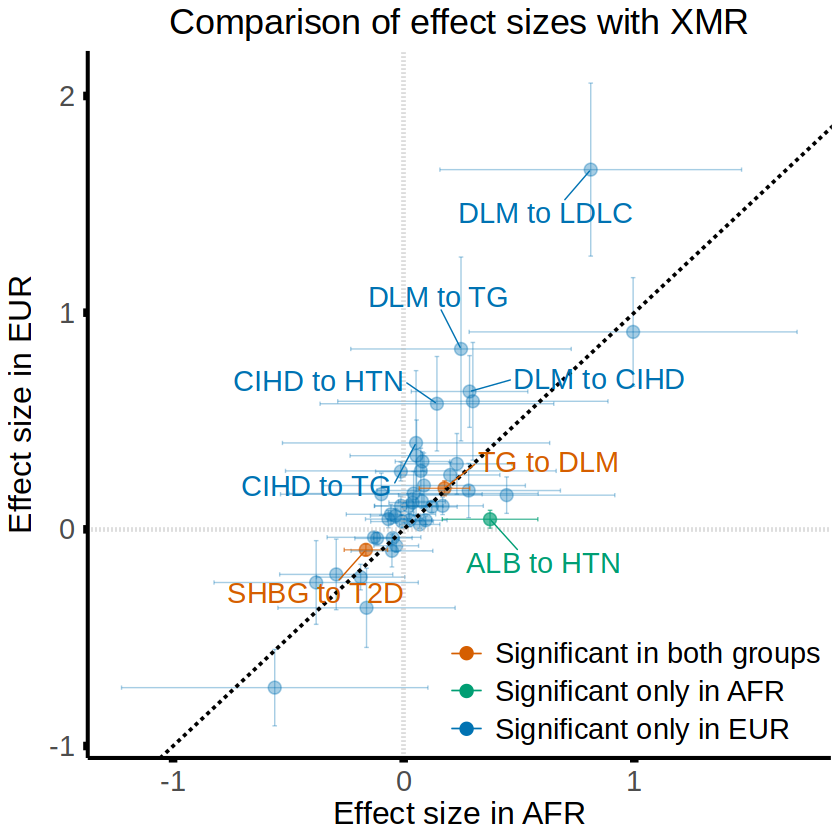

In [32]:
plot_scatter_AFR_EUR(
    df_afr = df_all_AFR,
    df_eur = df_all_EUR,
    beta_afr = paste0('beta_',"XMR"), beta_eur = paste0('beta_',"MRAPSS"),
    pval_afr = paste0('beta.pvalue_',"XMR"), pval_eur = paste0('beta.pvalue_',"MRAPSS"),
    se_afr = paste0('beta.se_',"XMR"), se_eur = paste0('beta.se_',"MRAPSS"),
    method_name = "XMR",
    code_to_abbr = code_to_abbr,
    legend_pos = c(0.73, 0.12),
    max_labels = c("both significant" = 8,
                   "only EUR significant" = 5,
                   "only AFR significant" = 5)
)

[1] "MRAPSS"


`height` was translated to `width`.
`height` was translated to `width`.


[1] "Egger"


`height` was translated to `width`.
`height` was translated to `width`.


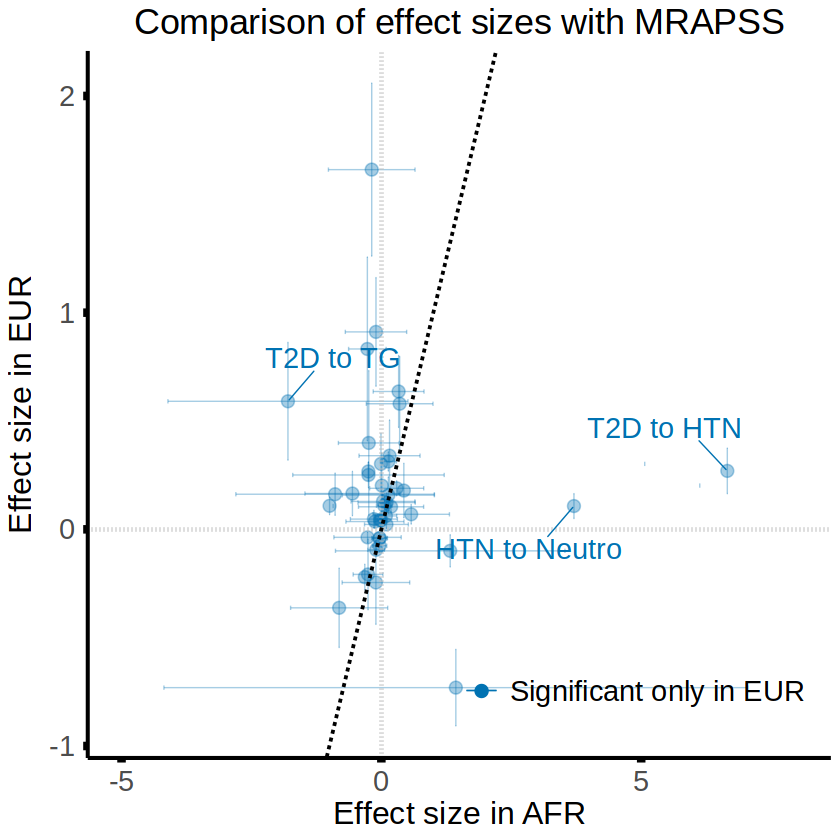

[1] "Weighted-mode"


`height` was translated to `width`.
`height` was translated to `width`.


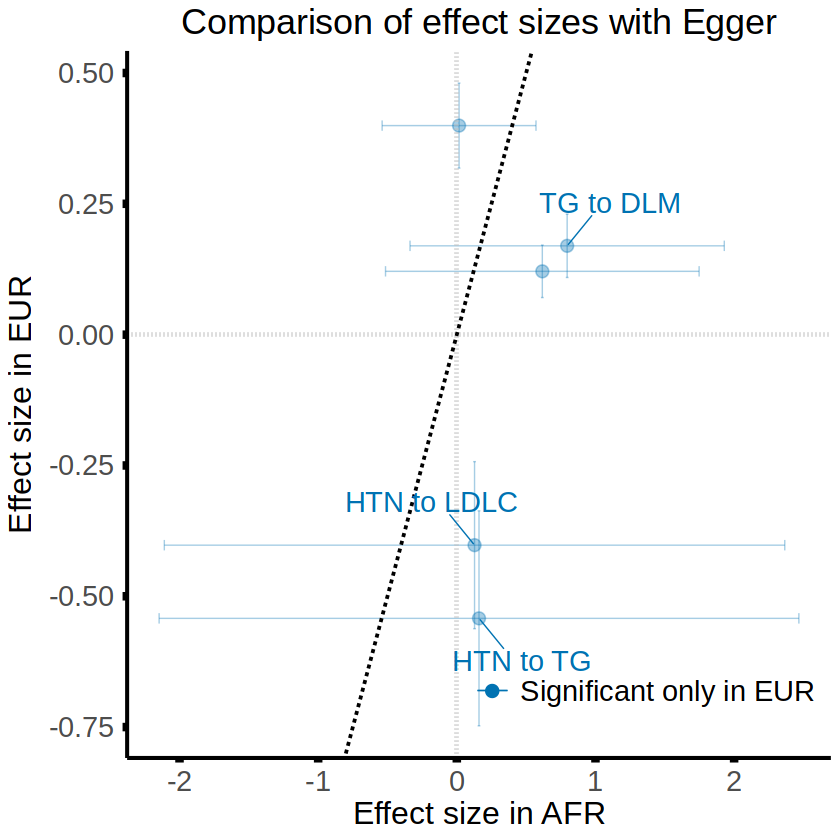

[1] "CAUSE"


`height` was translated to `width`.
`height` was translated to `width`.


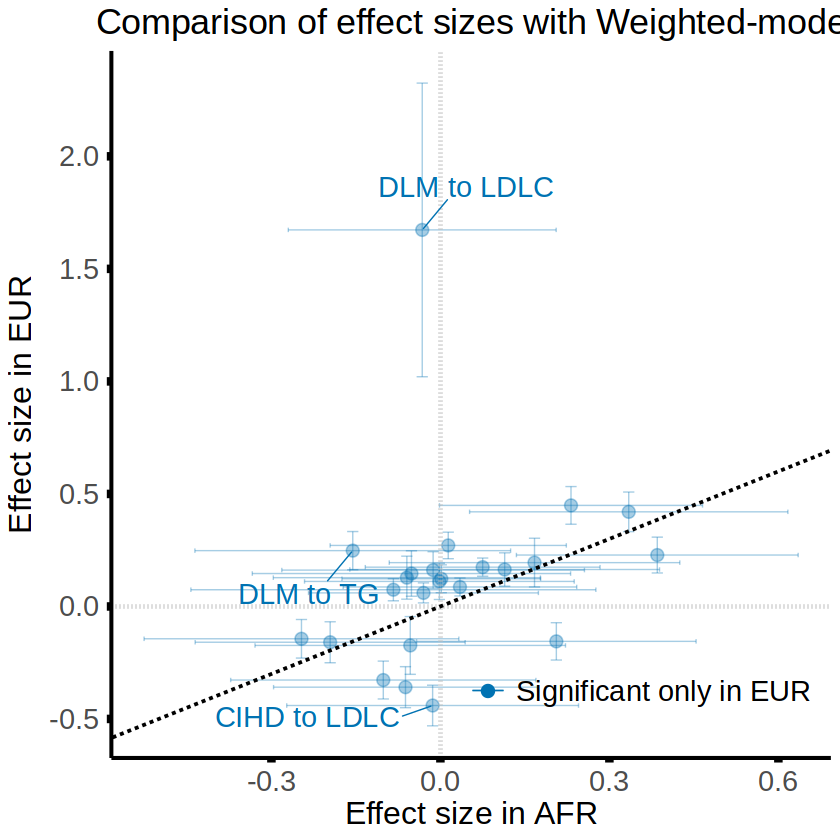

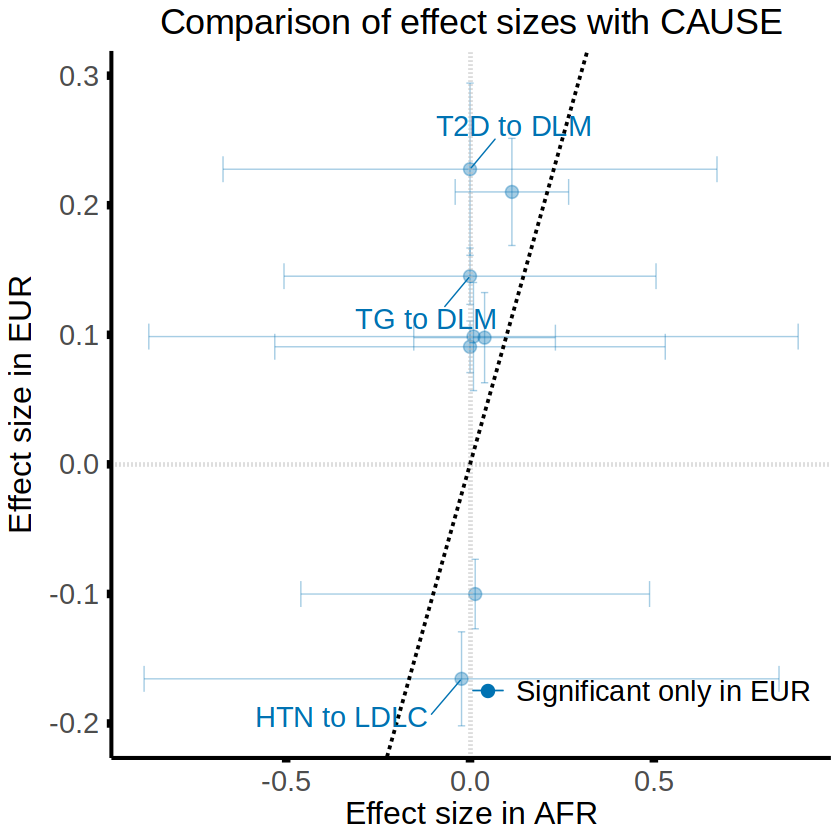

In [33]:
method_list = c('MRAPSS', 'Egger', 'Weighted-mode','CAUSE')

method_name_list = c('MRAPSS', 'Egger', 'Weighted-mode','CAUSE')



for(i in 1:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
        
    if(method == 'MRAPSS'){
        plot_scatter_AFR_EUR(
                            df_afr = df_all_AFR,
                            df_eur = df_all_EUR,
                            beta_afr = paste0('beta_',method), beta_eur = paste0('beta_',method),
                            pval_afr = paste0('beta.pvalue_',method), pval_eur = paste0('beta.pvalue_',method),
                            se_afr = paste0('beta.se_',method), se_eur = paste0('beta.se_',method),
                            method_name = method,
                            code_to_abbr = code_to_abbr,
                            legend_pos = c(0.73, 0.12),
                            max_labels = c("both significant" = 7,
                                           "only EUR significant" = 3,
                                           "only AFR significant" = 5),
                            x_lim=TRUE,
                            xl=-5,
                            xr=8
                            )
    }else{
        plot_scatter_AFR_EUR(
                            df_afr = df_all_AFR,
                            df_eur = df_all_EUR,
                            beta_afr = paste0('beta_',method), beta_eur = paste0('beta_',method),
                            pval_afr = paste0('beta.pvalue_',method), pval_eur = paste0('beta.pvalue_',method),
                            se_afr = paste0('beta.se_',method), se_eur = paste0('beta.se_',method),
                            method_name = method,
                            code_to_abbr = code_to_abbr,
                            legend_pos = c(0.73, 0.12),
                            max_labels = c("both significant" = 7,
                                           "only EUR significant" = 3,
                                           "only AFR significant" = 5)
                            )
    }
    
}

In [34]:
method_list = c('TEMR', 'IVW', 'Weighted-median', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')
method_name_list = method_list


for(i in 1:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
        
    plot_scatter_AFR_EUR(
                        df_afr = df_all_AFR,
                        df_eur = df_all_EUR,
                        beta_afr = paste0('beta_',method), beta_eur = paste0('beta_',method),
                        pval_afr = paste0('beta.pvalue_',method), pval_eur = paste0('beta.pvalue_',method),
                        se_afr = paste0('beta.se_',method), se_eur = paste0('beta.se_',method),
                        plot = FALSE,
                        method_name = method,
                        code_to_abbr = code_to_abbr,
                        legend_pos = c(0.73, 0.12),
                        max_labels = c("both significant" = 7,
                                       "only EUR significant" = 3,
                                       "only AFR significant" = 5)
                        )
    
}

[1] "TEMR"


`height` was translated to `width`.


[1] "IVW"


`height` was translated to `width`.


[1] "Weighted-median"


`height` was translated to `width`.


... (12 outputs left out)

[1] "dIVW"


`height` was translated to `width`.


[1] "MR-Lasso"


`height` was translated to `width`.
